# Lab 6: Stochastic Gradient Descent

In [1]:
import numpy as np

import matplotlib.pyplot as plt

rnd_state = np.random.RandomState(121212)

Consideriamo il seguente problema di ottimizzazione
$$
x^* \arg\min\limits_{x \in \mathbb{R}^d} F(x) := \mathbb{E}_Z[f(x, Z)].
$$
Inoltre, assumiamo che il gradiente $\nabla F(x)$ non sia computabile o sia troppo costoso da calcolare. In tale scenario, non possiamo usare gradient descent (oppure GD e\` troppo costoso). Alternativamente, possiamo considerare la seguente iterazione nota come Stochastic Gradient Descent (SGD)
$$
x_{k + 1} = x_k - \gamma_k \nabla f(x_k, z_k)
$$
dove $z_k$ e\` una realizzazione della variabile casuale $Z_k$, copia di $Z$.


A fini illustrativi, consideriamo il seguente esempio:
$$
\arg\min\limits_{x \in \mathbb{R}^d} F(x) := \frac{1}{2d} \| A x \|^2=\frac{1}{2d}\sum_{i=1}^d (\langle a_i,x\rangle)^2,
$$
dove abbiamo indicato con $a_i$ le righe di $A$.
Consideriamo $d = 20$, $x \in \mathbb{R}^{d}$ e $A \in \mathbb{R}^{d \times d}$. Nota che la valutazione stocastica, in questo caso, non e\` altro che il quadrato del prodotto di una riga della matrice $A$ e $x$

In [2]:
d = 20
A = rnd_state.randn(d, d)

def F(x):
  return (1/(2 * d)) * np.linalg.norm(A.dot(x), ord=2) ** 2


Implementiamo il gradiente $\nabla F$ e il gradiente stochastico $\nabla f_i = \nabla(x\mapsto \langle a_i,x\rangle^2)$ attraverso le due funzioni `grad_F(x)` e `grad_f(x, z)`



In [3]:
def grad_F(x):
  # TODO: ritorna il gradiente di F in x
  return (1/d)*np.transpose(A) @ (A.dot(x))

def grad_f(x, z):
  # In questo caso la realizzazione z e` un indice di A.
  a = A[z, :] # sia a la riga di A a indice z
  # TODO: ritorna il gradiente stocastico in x, z
  return  a*np.dot(a,x)

Definiamo ora la funzione
```
gd(x0, gamma, T)
```
La funzione prende $x_0 \in \mathbb{R}^{d}$, uno stepsize $\gamma$ e un numero massimo di iterazioni $T > 0$ ed esegue Gradient Descent. La funzione ritorna $x_T$ e la sequenza $x_k$.

In [4]:
def gd(x0, gamma, T):
  x = x0.copy()
  x_iters = np.empty((T + 1, x0.shape[0]))
  f_vals = np.empty((T + 1))
  x_iters[0] = x0.copy()
  f_vals[0] = F(x0)
  for k in range(1, T + 1):
    # TODO: implementa l'iterazione di Gradient Descent
    x  = x-gamma*grad_F(x)
    x_iters[k] = x.copy()
    f_vals[k] = F(x)
  return x, x_iters, f_vals



Analogamente, implementiamo SGD con la funzione
```
sgd(x0, gamma, alpha, T)
```
La funzione prende $x_0 \in \mathbb{R}^{d}$, due costanti $\gamma >0$ e $\alpha \geq 0$, un numero massimo di iterazioni $T > 0$ ed esegue Gradient Descent. La funzione ritorna $x_T$ e la sequenza $x_k$.

Lo step-size e\` implementato direttamente nella funzione come
$$
\gamma_k := \gamma k^{-\alpha}
$$
___
Hint: per generare interi casuali vedi
- [np.random.randint](https://numpy.org/doc/stable/reference/random/generated/numpy.random.randint.html)
- [np.random.choice](https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html)


In [5]:
def sgd(x0, gamma, alpha, T):
  x = x0.copy()
  x_iters = np.empty((T + 1, x0.shape[0]))
  f_vals = np.empty((T + 1))
  x_iters[0] = x0.copy()
  f_vals[0] = F(x0)
  for k in range(1, T + 1):
    gamma_k = gamma * (k**(-alpha))
    # TODO: campiona un indice random
    n,d=A.shape
    z = np.random.randint(0,n)
    # TODO: implementa l'iterazione di Stochastic Gradient Descent
    x  =x-gamma_k*grad_f(x,z)
    x_iters[k] = x.copy()
    f_vals[k] = F(x)
  return x, x_iters, f_vals



Eseguiamo le due funzioni per il target proposto e confrontiamo i risultati dei due algoritmi

In [29]:
# Gradient Descent
x0 = np.ones(d)

# TODO: fissa 1/L come stepsize
L=np.linalg.norm(np.transpose(A)@ A, ord=2)
gamma = d/L


T = 5000

x_gd, iters_gd, fvals_gd = gd(x0, gamma, T)

In [30]:
# Stochastic Gradient Descent

# TODO: scegli uno stepsize per stochastic gradient descent
L=np.linalg.norm(np.transpose(A)@ A, ord=2)
gamma = 1/L

# TODO: scegli un esponente per lo stepsize (nota che con 0, lo stepsize sara` costante)
alpha =1/L
#alpha=0.5
x_sgd, iters_sgd, fvals_sgd = sgd(x0, gamma, alpha, T)


Plottiamo le sequenza $\| x_k - x^* \|$

Text(0, 0.5, '$\\|x_k - x^*\\|$')

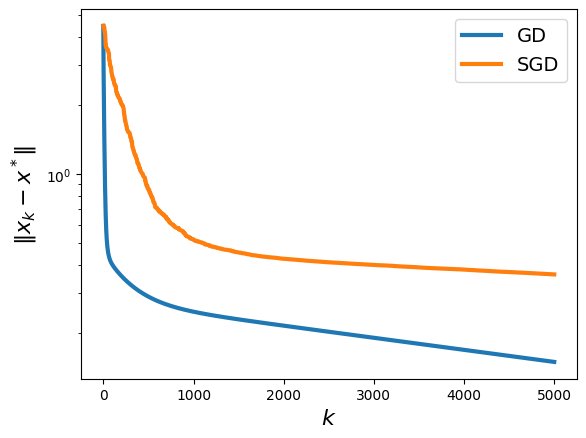

In [31]:
gd_norm = np.linalg.norm(iters_gd, axis=1, ord=2)
sgd_norm = np.linalg.norm(iters_sgd, axis=1, ord=2)

fig, ax = plt.subplots()
ax.plot(range(len(gd_norm)),  gd_norm, '-', lw=3, label="GD")
ax.plot(range(len(sgd_norm)),sgd_norm, '-', lw=3, label="SGD")
ax.legend(fontsize=14)
ax.set_yscale("log")
ax.set_xlabel("$k$", fontsize=16)
ax.set_ylabel("$\|x_k - x^*\|$", fontsize=16)

plottiamo i valori della funzione target $F$ sulle iterate

Text(0, 0.5, '$F(x_k)$')

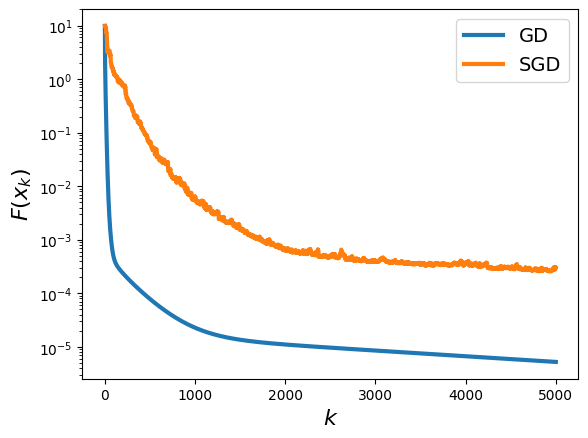

In [32]:
fig, ax = plt.subplots(1, 1)
ax.plot(range(len(fvals_gd)),  fvals_gd, '-' ,lw=3, label="GD")
ax.plot(range(len(fvals_sgd)), fvals_sgd, '-',lw=3, label="SGD")
ax.legend(fontsize=14)
ax.set_yscale("log")
ax.set_xlabel("$k$", fontsize=16)
ax.set_ylabel("$F(x_k)$", fontsize=16)

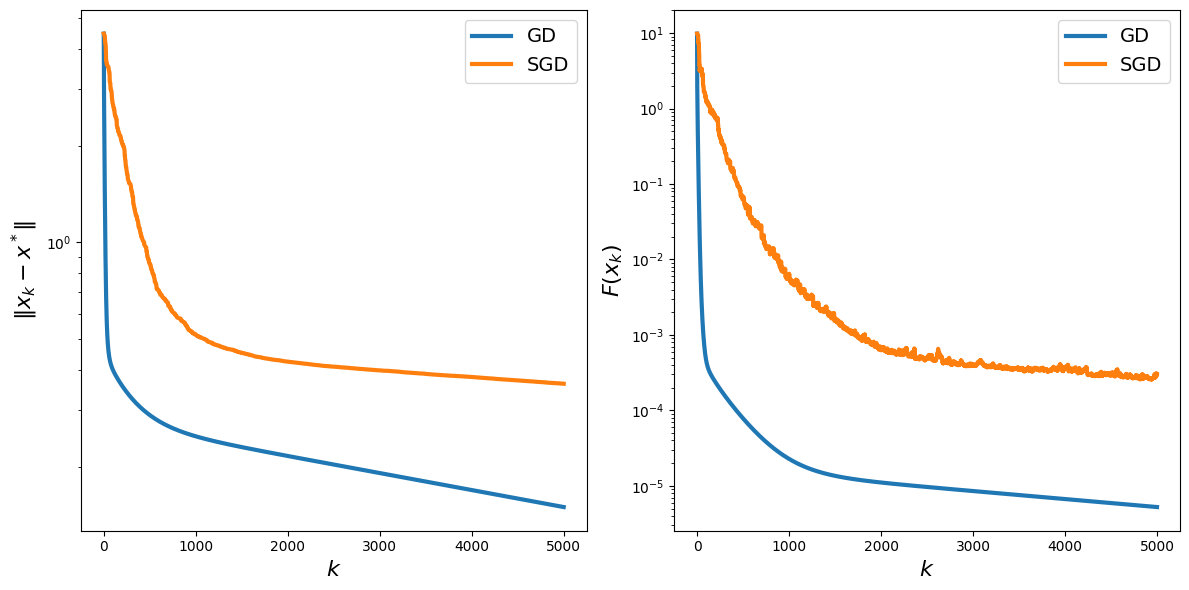

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

# Plotting \|x_k - x^*\|
axs[0].plot(range(len(gd_norm)),  gd_norm, '-', lw=3, label="GD")
axs[0].plot(range(len(sgd_norm)), sgd_norm, '-', lw=3, label="SGD")
axs[0].legend(fontsize=14)
axs[0].set_yscale("log")
axs[0].set_xlabel("$k$", fontsize=16)
axs[0].set_ylabel("$\|x_k - x^*\|$", fontsize=16)

# Plotting F(x_k)
axs[1].plot(range(len(fvals_gd)),  fvals_gd, '-' ,lw=3, label="GD")
axs[1].plot(range(len(fvals_sgd)), fvals_sgd, '-',lw=3, label="SGD")
axs[1].legend(fontsize=14)
axs[1].set_yscale("log")
axs[1].set_xlabel("$k$", fontsize=16)
axs[1].set_ylabel("$F(x_k)$", fontsize=16)

plt.tight_layout()
plt.show()

## Tuning the step-size
Fissa un valore per $\alpha$ e definisci una lista di valori per $\gamma$

In [34]:
x0 = np.ones(d)
# TODO: definisci una lista di gamma
L=np.linalg.norm(np.transpose(A)@ A, ord=2)
gammas = [1/L, 2/L, 2/(L+1), 1/(2*L)]
T = 5000
values = []
norms = []
alpha = 0.5


for (i, gamma) in enumerate(gammas):
  x_sgd, iters_sgd, fvals_sgd = sgd(x0, gamma, alpha, T)
  values.append(fvals_sgd)
  norms.append(np.linalg.norm(iters_sgd, axis=1, ord=2))


Plottiamo i risultati ottenuti

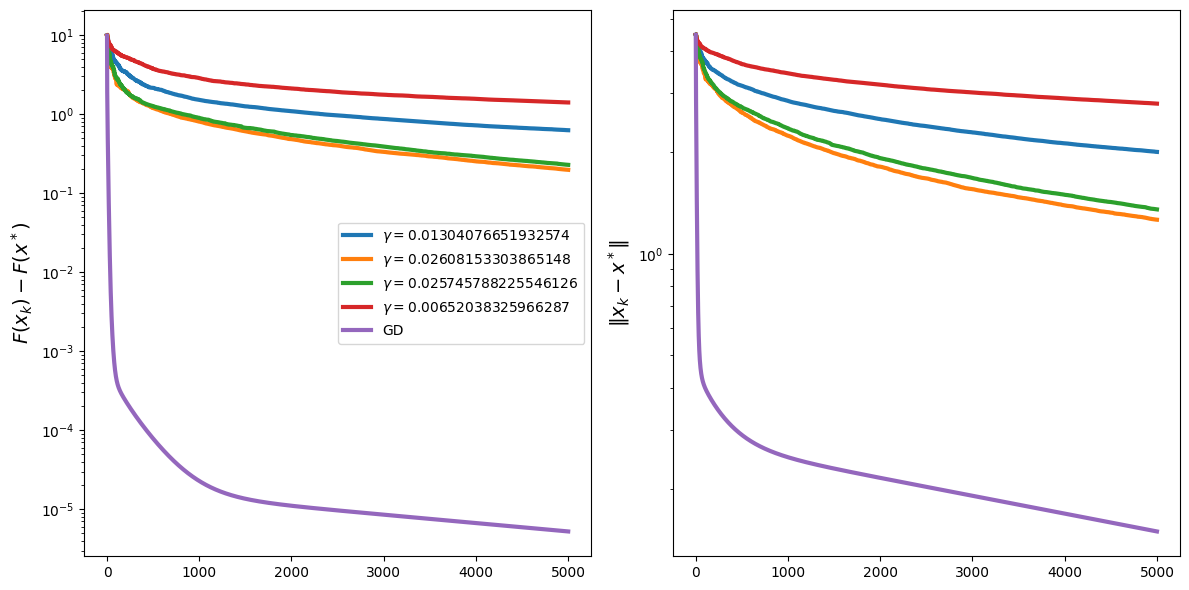

In [35]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

for i in range(len(values)):
  ax1.plot(values[i], '-', lw=3, label='$\gamma = {}$'.format(gammas[i]))
  ax2.plot( norms[i], '-', lw=3, label='$\gamma = {}$'.format(gammas[i]))
ax1.plot(fvals_gd, '-', lw=3, label='GD')
ax2.plot( gd_norm, '-', lw=3, label='GD')
ax1.set_ylabel("$F(x_k) - F(x^*)$",fontsize=14)
ax2.set_ylabel("$\|x_k - x^*\|$"  ,fontsize=14)
ax1.set_yscale("log")
ax2.set_yscale("log")
ax1.legend()
fig.tight_layout()

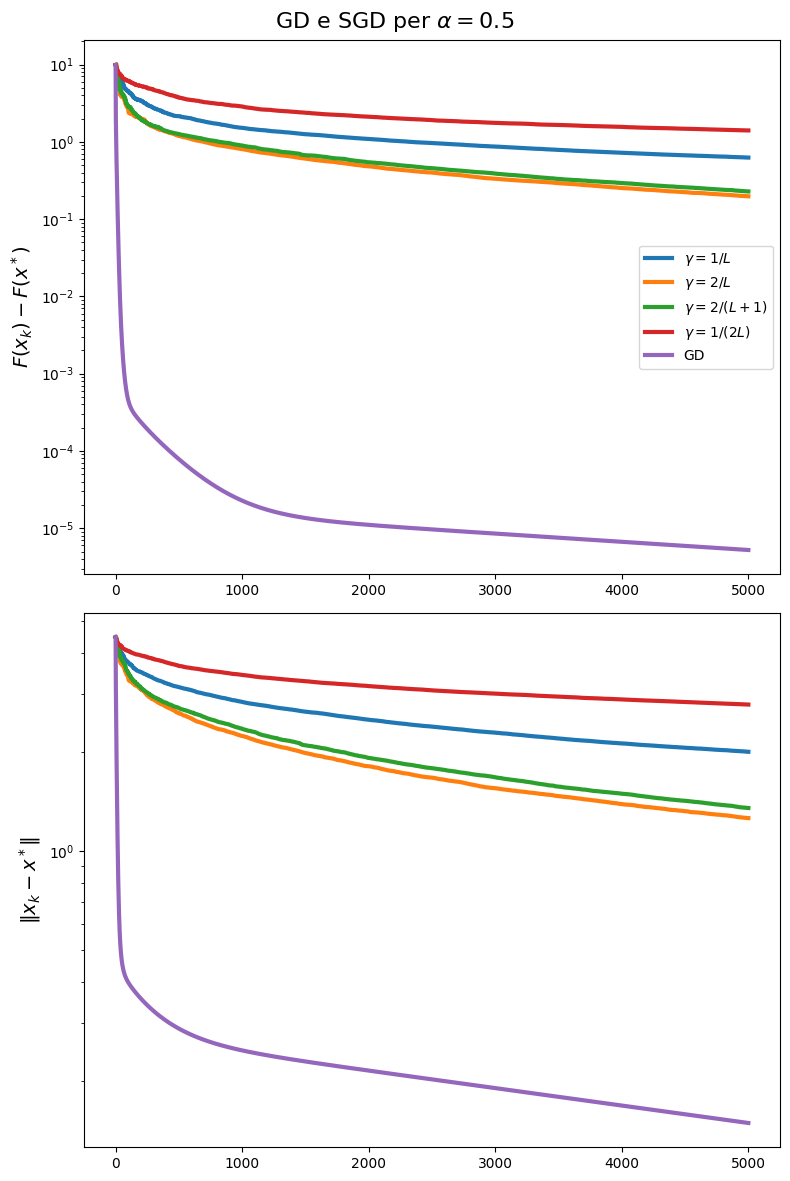

In [36]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 12))

selected_gammas = [0, 1, 2, 3]  # Selecting only five gammas

gamma_labels = ['$\gamma = 1/L$', '$\gamma = 2/L$', '$\gamma = 2/(L+1)$', '$\gamma = 1/(2L)$']

for i in selected_gammas:
    ax1.plot(values[i], '-', lw=3, label=gamma_labels[i])
    ax2.plot(norms[i], '-', lw=3, label=gamma_labels[i])

ax1.plot(fvals_gd, '-', lw=3, label='GD')
ax2.plot(gd_norm, '-', lw=3, label='GD')

ax1.set_ylabel("$F(x_k) - F(x^*)$", fontsize=14)
ax2.set_ylabel("$\|x_k - x^*\|$", fontsize=14)
ax1.set_yscale("log")
ax2.set_yscale("log")
ax1.legend()
# Add the title with alpha_value
fig.suptitle(r'GD e SGD per $\alpha={}$'.format(alpha), fontsize=16)
fig.tight_layout()
plt.show()

Ripetiamo l'esperimento ma tenendo fissato $\gamma$ e definendo una lista di $\alpha$

In [37]:
x0 = np.ones(d)
# TODO: definisci una lista di alpha
alphas = [ 2/3, 1/2, 1/3, 1/5, 1/10, 1/L] # piu alpha piccolo piu gamma grande
T = 5000
values = []
norms = []
# TODO: fissa un valore per gamma
gamma = 1/L

for (i, alpha) in enumerate(alphas):
  x_sgd, iters_sgd, fvals_sgd = sgd(x0, gamma, alpha, T)
  values.append(fvals_sgd)
  norms.append(np.linalg.norm(iters_sgd, axis=1, ord=2))


Plottiamo i risultati

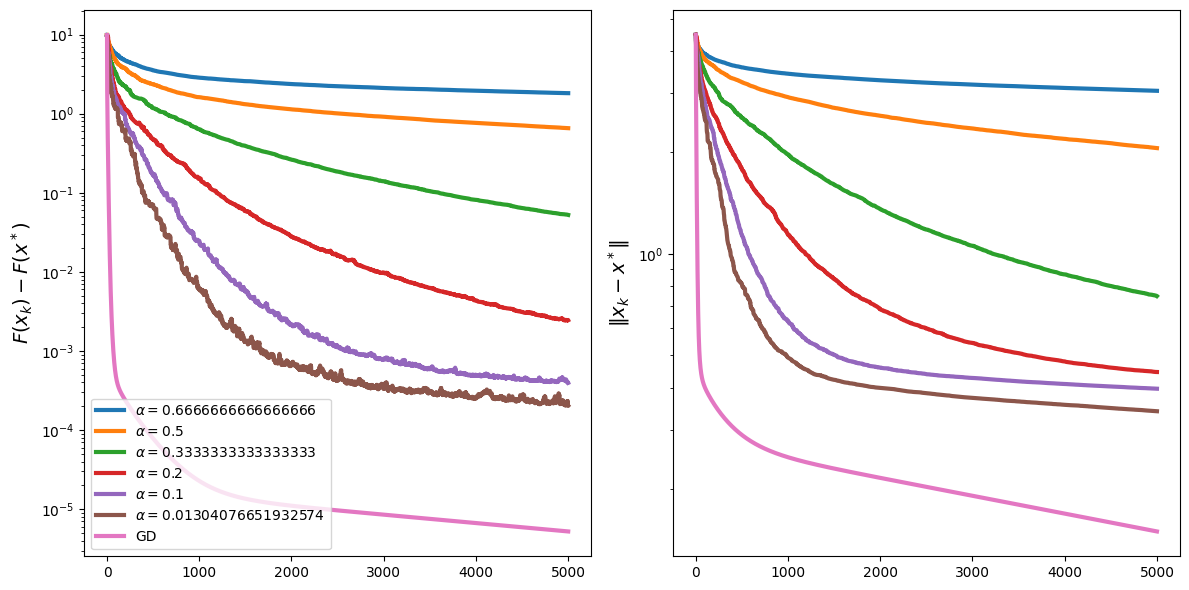

In [38]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

for i in range(len(alphas)):
  ax1.plot(values[i], '-', lw=3, label='$\\alpha = {}$'.format(alphas[i]))
  ax2.plot( norms[i], '-', lw=3, label='$\\alpha = {}$'.format(alphas[i]))
ax1.plot(fvals_gd, '-', lw=3, label='GD')
ax2.plot( gd_norm, '-', lw=3, label='GD')
ax1.set_ylabel("$F(x_k) - F(x^*)$",fontsize=14)
ax2.set_ylabel("$\|x_k - x^*\|$"  ,fontsize=14)
ax1.set_yscale("log")
ax2.set_yscale("log")
ax1.legend()
fig.tight_layout()

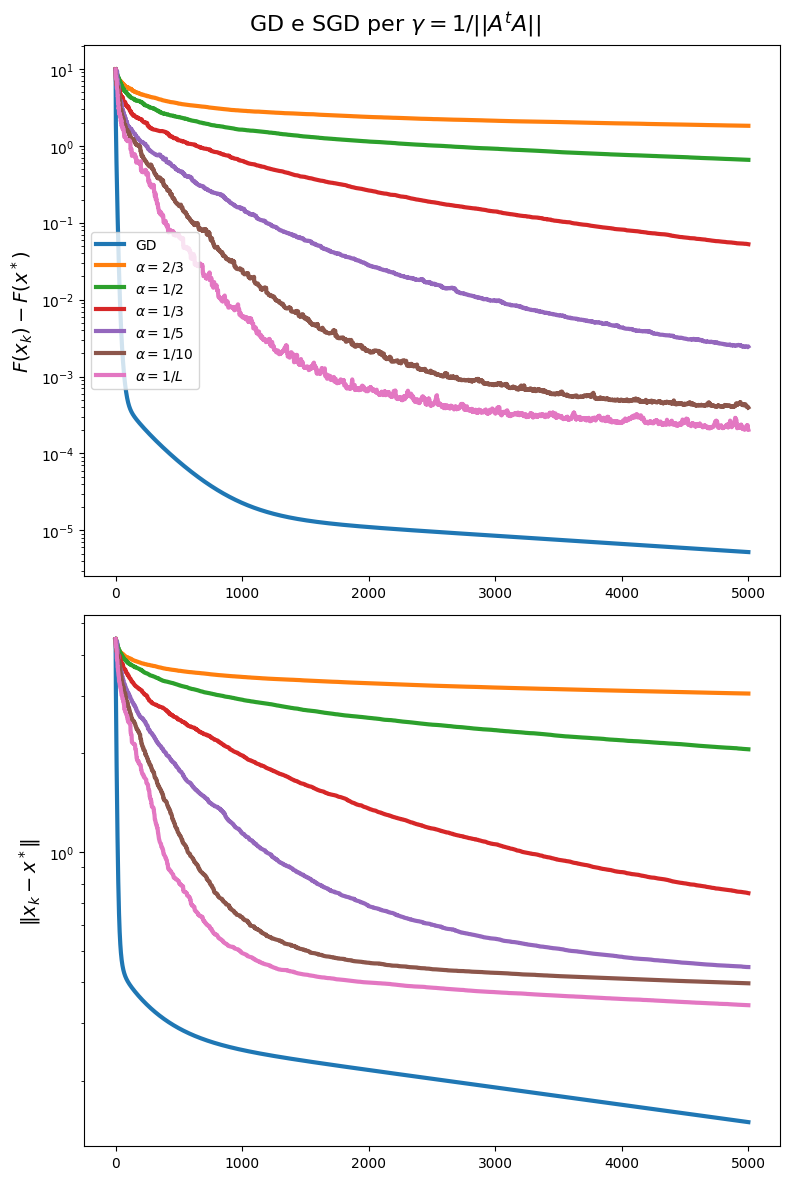

In [39]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 12))

selected_alphas = [0, 1, 2, 3, 4, 5]  # Selecting all alphas

alpha_labels = ['$\\alpha = 2/3$', '$\\alpha = 1/2$', '$\\alpha = 1/3$', '$\\alpha = 1/5$', '$\\alpha = 1/10$', '$\\alpha = 1/L$','GD']

ax1.plot(fvals_gd, '-', lw=3, label='GD')
ax2.plot( gd_norm, '-', lw=3, label='GD')
for i in selected_alphas:
    ax1.plot(values[i], '-', lw=3, label=alpha_labels[i])
    ax2.plot(norms[i], '-', lw=3, label=alpha_labels[i])

ax1.set_ylabel("$F(x_k) - F(x^*)$", fontsize=14)
ax2.set_ylabel("$\|x_k - x^*\|$", fontsize=14)
ax1.set_yscale("log")
ax2.set_yscale("log")
ax1.legend()
fig.suptitle(r'GD e SGD per $\gamma= 1/||A^tA||$', fontsize=16)
fig.tight_layout()

plt.show()

Adesso fissa $\alpha = 0$ e scegli una costante ragionevole per $\gamma$. Confronta il risultato con GD

In [40]:
# Stochastic Gradient Descent

# TODO: scegli uno stepsize per stochastic gradient descent
gamma = 1/L
alpha=0

T = 50000

# TODO: esegui SGD
x_sgd, iters_sgd, fvals_sgd = sgd(x0, gamma, alpha, T)
# TODO: esegui GD
x_gd, iters_gd, fvals_gd = gd(x0, gamma, T)

Plottiamo i function values

Text(0.5, 0.98, 'GD e SGD per $\\alpha=0$ e $\\gamma= 1/||A^tA||$')

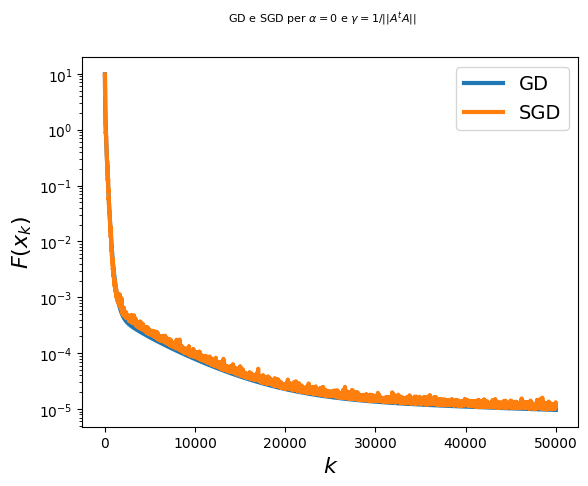

In [41]:
fig, ax = plt.subplots(1, 1)
ax.plot(range(len(fvals_gd)),  fvals_gd, '-' ,lw=3, label="GD")
ax.plot(range(len(fvals_sgd)), fvals_sgd, '-',lw=3, label="SGD")
ax.legend(fontsize=14)
ax.set_yscale("log")
ax.set_xlabel("$k$", fontsize=16)
ax.set_ylabel("$F(x_k)$", fontsize=16)
fig.suptitle(r'GD e SGD per $\alpha=0$ e $\gamma= 1/||A^tA||$', fontsize=8)

## Mini-batch Gradient Descent
Un'alternativa a Stochastic gradient descent e\` Mini-batch Gradient Descent (MBGD).

Tale algoritmo consiste nel computare il gradiente utilizzando dei batch di dati random invece che solo un punto come in SGD.

Questo, fornisce un compromesso tra l'efficienza di SGD e la stabilita\` di GD. Tuttavia cio aggiunge la batch size come parametro aggiuntivo da tunare.



Implementiamo quindi tale algoritmo mediante la funzione
```
mbgd(x0, gamma, alpha, batch_size, T)
```

In [ ]:
def mbgd(x0, gamma, alpha, batch_size, T):
  x = x0.copy()
  x_iters = np.empty((T + 1, x0.shape[0]))
  f_vals = np.empty((T + 1))
  x_iters[0] = x0.copy()
  f_vals[0] = F(x0)
  for k in range(1, T + 1):
    gamma_k = gamma * (k**(-alpha))
    # TODO: scegli batch_size indici random senza replacement (hint: vedi np.random.choice)
    n,m=A.shape
    batch_indices = np.random.choice(n, batch_size)
    X_batch = A[batch_indices, :]
    # TODO: computa il gradiente usando il batch previa campionato
    nabla_f = 1/len(batch_indices) * X_batch.T @ np.dot(X_batch,x)
    # TODO: implementa l'iterazione di Stochastic Gradient Descent
    x  = x-gamma_k*nabla_f
    x_iters[k] = x.copy()
    f_vals[k] = F(x)
  return x, x_iters, f_vals



Fissando `batch_size = 10`, eseguiamo MBGD e confrontiamo il risultato con gli altri algoritmi

In [ ]:
# Gradient Descent
x0 = np.ones(d)
batch_size = 10
alpha = 1/2

T = 100

# TODO: fissa 1/L come stepsize
L=np.linalg.norm(np.transpose(A)@ A, ord=2)
gamma = 1/L


# TODO: esegui SGD
x_sgd, iters_sgd, fvals_sgd =sgd(x0, gamma, alpha, T)
# TODO: esegui GD
x_gd, iters_gd, fvals_gd = gd(x0, gamma, T)
# TODO: esegui MBGD
x_mbgd, iters_mbgd, fvals_mbgd = mbgd(x0, gamma, alpha, batch_size, T)

Plottiamo il risultato

Text(0.5, 0.98, 'Batch size=10, $\\gamma= 1/||A^tA||$ e $\\alpha=0.5$ ')

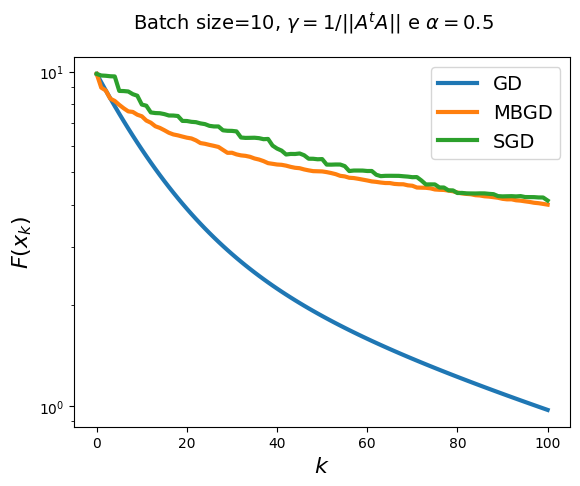

In [ ]:
fig, ax = plt.subplots(1, 1)
ax.plot(range(len(fvals_gd)),  fvals_gd, '-' ,lw=3, label="GD")
ax.plot(range(len(fvals_mbgd)),  fvals_mbgd, '-' ,lw=3, label="MBGD")
ax.plot(range(len(fvals_sgd)), fvals_sgd, '-',lw=3, label="SGD")
ax.legend(fontsize=14)
ax.set_yscale("log")
ax.set_xlabel("$k$", fontsize=16)
ax.set_ylabel("$F(x_k)$", fontsize=16)
fig.suptitle(r'Batch size=10, $\gamma= 1/||A^tA||$ e $\alpha=0.5$ ', fontsize=14)
#fig.suptitle(r'GD e SGD per $\alpha={}$'.format(alpha), fontsize=16)

Fissa $\alpha = 0$ e $\gamma$ a un valore ragionevole. Definisci una lista di valori di batch size e osserva il risultato

In [ ]:
x0 = np.ones(d)
# TODO: definisci una lista di batch size
batch_sizes = [2, 16, 32, 64]
T = 100
alpha = 0
values = []
norms = []

# TODO: fissa un valore per gamma
gamma = 1/L

for (i, bs) in enumerate(batch_sizes):
  # TODO: esegui MBGD
  x_mbgd, iters_mbgd, fvals_mbgd =mbgd(x0, gamma, alpha, bs, T)
  values.append(fvals_mbgd)
  norms.append(np.linalg.norm(iters_mbgd, axis=1, ord=2))


x_gd, iters_gd, fvals_gd = gd(x0, gamma, T)
gd_norm = np.linalg.norm(iters_gd, axis=1, ord=2)


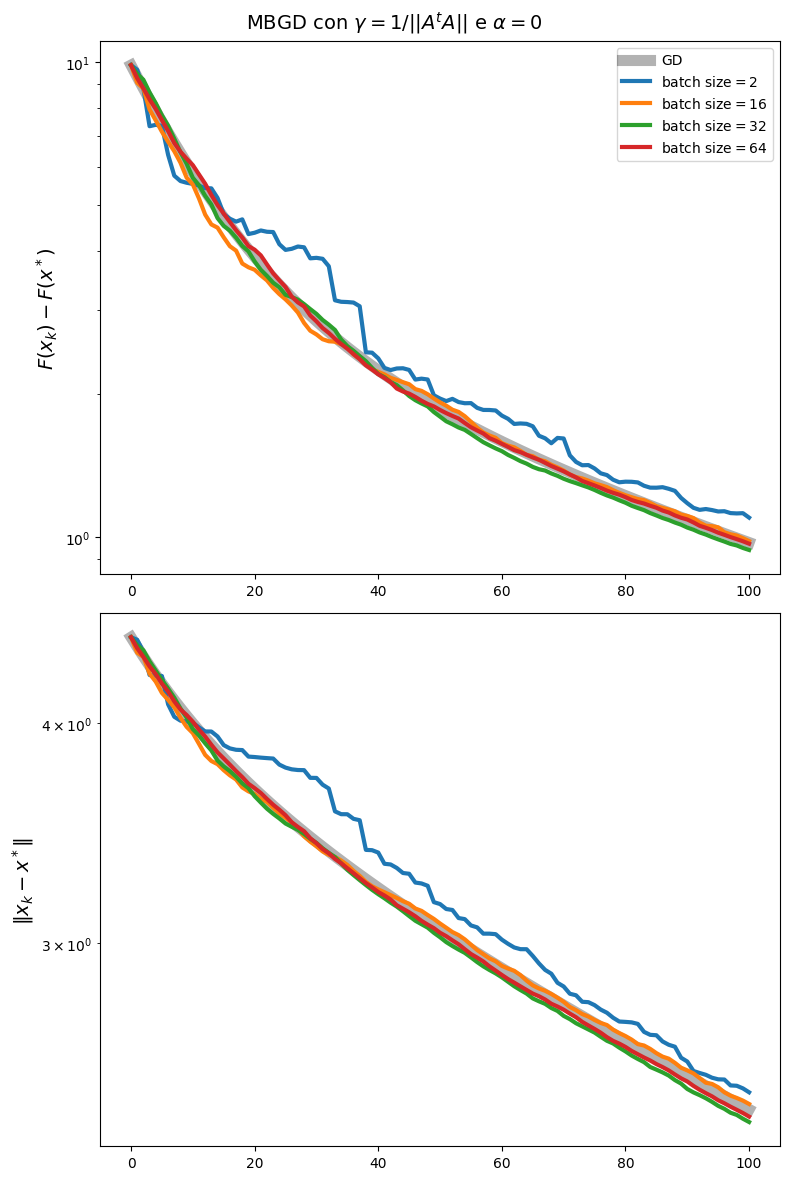

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 12))

ax1.plot(fvals_gd, '-', lw=8, alpha=0.3, c='black', label='GD')
ax2.plot( gd_norm, '-', lw=8, alpha=0.3, c='black', label='GD')

for i in range(len(batch_sizes)):
  ax1.plot(values[i], '-', lw=3, label='batch size$ = {}$'.format(batch_sizes[i]))
  ax2.plot( norms[i], '-', lw=3, label='batch size$ = {}$'.format(batch_sizes[i]))
ax1.set_ylabel("$F(x_k) - F(x^*)$",fontsize=14)
ax2.set_ylabel("$\|x_k - x^*\|$"  ,fontsize=14)
ax1.set_yscale("log")
ax2.set_yscale("log")
ax1.legend()
fig.suptitle(r'MBGD con $\gamma= 1/||A^tA||$ e $\alpha=0$ ', fontsize=14)
fig.tight_layout()

## Linear regression
Dato un dataset $(x_i, y_i)_{i = 1}^n$ con $x_i \in \mathbb{R}^d$ e $y_i = w_*^\intercal x_i$, vogliamo risolvere il problema
$$
w_* \in \arg\min\limits_{w \in \mathbb{R}^d} F(w) = \frac{1}{2n}\sum\limits_{i = 1}^n (w^\intercal x_i - y_i)^2
$$
Consideriamo il caso $d = 100$

In [ ]:
d = 100
n = 10000
X = rnd_state.randn(n, d)


w_star = np.ones(d)
Y = X.dot(w_star)

def F(X, Y, w):
  return (1/(2* n)) * np.sum(np.square(X.dot(w) - Y)) ** 2


Reimplementiamo i 3 algoritmi: GD, SGD e MBGD

In [ ]:
def gd(X, Y, w0, gamma, T):
  w = w0.copy()
  x_iters = np.empty((T + 1, w0.shape[0]))
  f_vals = np.empty((T + 1))
  x_iters[0] = w0.copy()
  f_vals[0] = F(X, Y, w0)
  for k in range(1, T + 1):
    # TODO: computa il gradiente della funzione target
    nabla_f = 1/n * np.transpose(X) @ (np.dot(X, w)-Y)
    # TODO: implementa l'iterazione di Gradient Descent
    w  = w - gamma* nabla_f
    x_iters[k] = w.copy()
    f_vals[k] = F(X, Y, w)
  return w, x_iters, f_vals

def sgd(X, Y, w0, gamma, alpha, T):
  w = w0.copy()
  x_iters = np.empty((T + 1, w0.shape[0]))
  f_vals = np.empty((T + 1))
  x_iters[0] = w0.copy()
  f_vals[0] = F(X, Y, w0)
  for k in range(1, T + 1):
    gamma_k = gamma * (k**(-alpha))
    # TODO: campiona un indice random
    z =np.random.randint(0,n)
    # TODO: computa il gradiente stocastico della funzione target
    nabla_f =  np.dot(X[z,:].T, np.dot(X[z,:], w)-Y[z])
    # TODO: implementa l'iterazione di Stochastic Gradient Descent
    w  =w-gamma_k*nabla_f
    x_iters[k] = w.copy()
    f_vals[k] = F(X, Y, w)
  return w, x_iters, f_vals

def mbgd(X, Y, w0, gamma, alpha, batch_size, T):
  w = w0.copy()
  x_iters = np.empty((T + 1, w0.shape[0]))
  f_vals = np.empty((T + 1))
  x_iters[0] = w0.copy()
  f_vals[0] = F(X, Y, w0)
  for k in range(1, T + 1):
    gamma_k = gamma * (k**(-alpha))
    # TODO: scegli batch_size indici random senza replacement (hint: vedi np.random.choice)
    batch_indices =np.random.choice(n, batch_size)
    X_batch=X[batch_indices, :]
    # TODO: computa il gradiente usando il batch previa campionato
    nabla_f = 1/len(batch_indices)*(np.dot(X_batch.T, np.dot(X_batch, w)-Y[batch_indices]))
    # TODO: implementa l'iterazione di Stochastic Gradient Descent
    w  = w-gamma_k*nabla_f
    x_iters[k] = w.copy()
    f_vals[k] = F(X, Y, w)
  return w, x_iters, f_vals





Eseguiamo SGD e GD e confrontiamo i risultati

In [ ]:
T = 50
w_0 = np.zeros(d)

# TODO: fissa una batch size
batch_size = 2

# TODO: scegli uno step-size appropriato (gamma e alpha)
L=np.linalg.norm(X.T @ X, ord=2)
gamma = 1/L
alpha = 0.5

x_sgd, iters_sgd, fvals_sgd = sgd(X, Y, w_0, gamma, alpha, T)
x_mbgd, iters_mbgd, fvals_mbgd = mbgd(X, Y, w_0, gamma, alpha, batch_size, T)
x_gd, iters_gd, fvals_gd = gd(X, Y, w_0, gamma, T)

Confrontiamo i risultati

Text(0.5, 0.98, 'Batch size=10, $\\gamma= 1/||X^tX||$ e $\\alpha=0.5$ ')

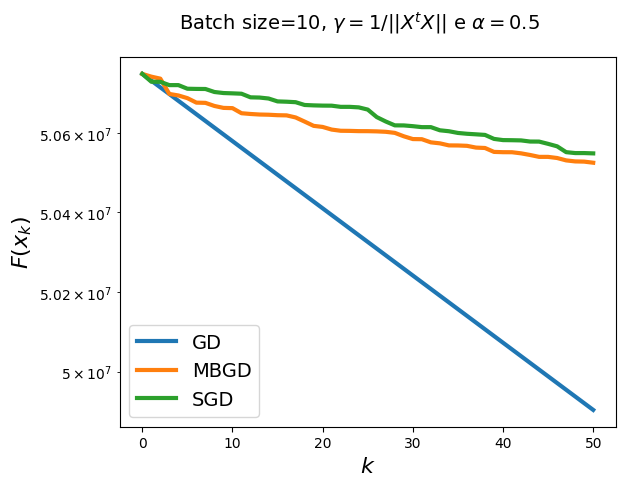

In [ ]:
fig, ax = plt.subplots(1, 1)
ax.plot(range(len(fvals_gd)), fvals_gd,  '-', lw=3, label="GD")
ax.plot(range(len(fvals_mbgd)), fvals_mbgd, '-', lw=3, label="MBGD")
ax.plot(range(len(fvals_sgd)), fvals_sgd,  '-', lw=3, label="SGD")
ax.legend(fontsize=14)
ax.set_yscale("log")
ax.set_xlabel("$k$", fontsize=16)
ax.set_ylabel("$F(x_k)$", fontsize=16)
fig.suptitle(r'Batch size=10, $\gamma= 1/||X^tX||$ e $\alpha=0.5$ ', fontsize=14)

Fissa i parametri e definisci una lista di valori di batch size. Confronta i risultati ottenuti con GD e SGD

In [ ]:
w0 = np.full(d, 10.0)

# TODO: definisci una lista di alpha
batch_size = [2,8, 32]
T = 100
values = []
norms = []

# TODO: fissa un valore per gamma e alpha
gamma = 1/L
alpha = 0

for (i, bs) in enumerate(batch_size):
  # TODO: esegui MBGD
  x_mbgd, iters_mbgd, fvals_mbgd = mbgd(X, Y, w_0, gamma, alpha, bs, T)
  values.append(fvals_mbgd)
  norms.append(np.linalg.norm(iters_mbgd - w_star, axis=1, ord=2))


# TODO: esegui SGD e GD
x_sgd, iters_sgd, fvals_sgd = sgd(X, Y, w_0, gamma, alpha, T)
x_gd, iters_gd, fvals_gd =  gd(X, Y, w_0, gamma, T)

gd_norm = np.linalg.norm(iters_gd - w_star, axis=1, ord=2)
sgd_norm = np.linalg.norm(iters_sgd - w_star, axis=1, ord=2)


Plottiamo i risultati

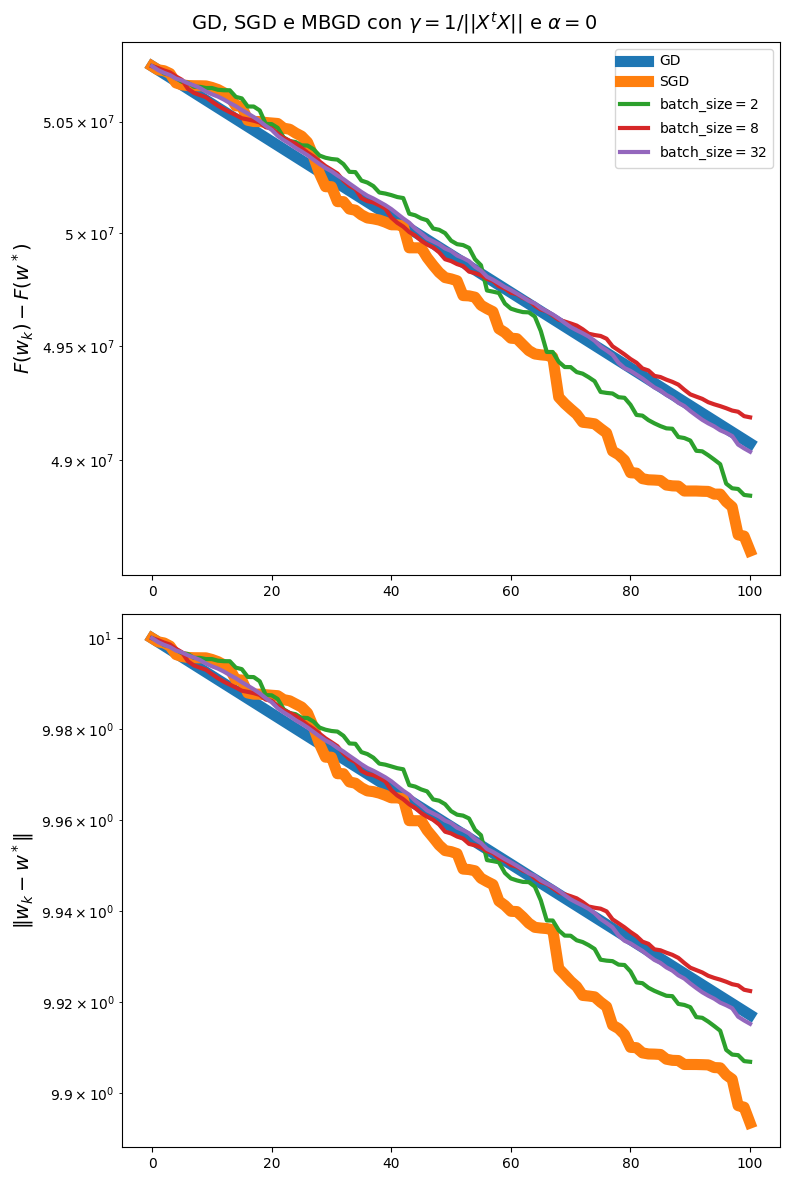

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 12))

ax1.plot(fvals_gd, '-', lw=8, label='GD')
ax2.plot( gd_norm, '-', lw=8, label='GD')
ax1.plot(fvals_sgd, '-', lw=8, label='SGD')
ax2.plot( sgd_norm, '-', lw=8, label='SGD')
for i in range(len(values)):
  ax1.plot(values[i], '-', lw=3, label='batch_size$ = {}$'.format(batch_size[i]))
  ax2.plot( norms[i], '-', lw=3, label='batch_size$ = {}$'.format(batch_size[i]))
ax1.set_ylabel("$F(w_k) - F(w^*)$",fontsize=14)
ax2.set_ylabel("$\|w_k - w^*\|$"  ,fontsize=14)
ax1.set_yscale("log")
ax2.set_yscale("log")
ax1.legend()
fig.suptitle(r'GD, SGD e MBGD con $\gamma= 1/||X^tX||$ e $\alpha=0$ ', fontsize=14)
fig.tight_layout()